## Class Imbalance >> when one class has higher percentage
### Handle:
#### Unsampling
#### Downsampling
#### SMOTE

In [1]:
import pandas as pd
import numpy as np


np.random.seed(1) # for reproducibility of result

In [1]:
no_samples = 1000 # dataset have 1000 samples
class_0_ratio = 0.9 # 90% records are 0
no_class_0 = int(no_samples*class_0_ratio) # 1000 * 0.9 
no_class_1 = 100 # class 1 have 100 records

In [2]:
no_class_0,no_class_1

(900, 100)

In [38]:
class_0 = {'feature1': np.random.normal(0,1,no_class_0),
           'feature2': np.random.normal(0,1,no_class_0),
           'target': [0]*no_class_0} # 0 repeat = no_class_0

In [39]:
class_0

{'feature1': array([ 1.79761774e+00, -1.58154588e+00,  1.32044365e-01, -2.44990537e+00,
         1.29439390e+00,  1.61063696e-01,  8.94349949e-01,  1.25373027e+00,
         2.86323332e-01,  4.16442232e-01,  3.06500650e-01, -3.06375935e-01,
         3.73047976e-01,  7.71506212e-01, -6.07899322e-03, -2.18872028e+00,
        -3.96318055e-01, -3.49250409e-01, -1.56720929e+00,  2.26727933e-01,
         2.88563279e-02, -8.14301120e-01,  4.93043142e-01,  9.11190010e-01,
        -1.13700147e+00,  1.20761026e-01, -1.00863956e+00,  8.27635525e-01,
         2.05087297e+00, -1.02363600e+00, -2.47817184e-01,  6.83939447e-01,
        -2.75268259e-01, -1.17596319e+00,  2.59155813e-01, -1.04604203e+00,
        -5.97775913e-01, -2.51583062e+00, -3.98114433e-01,  3.85342215e-01,
        -1.04636063e+00, -6.32375228e-01,  5.68656671e-02, -9.35520749e-01,
         1.43877273e-01, -1.02266805e-01,  1.05650278e+00,  2.56340626e-01,
        -1.97067193e-02, -5.55634660e-02, -1.50935733e+00,  5.92323395e-03,


In [40]:
 class_0 = pd.DataFrame(class_0) 

In [41]:
class_0


,feature1,feature2,target
0,1.797618,-1.055213,0
1,-1.581546,-0.101732,0
2,0.132044,0.165406,0
3,-2.449905,1.415364,0
4,1.294394,-0.426843,0
...,...,...,...
895,-0.087213,-0.704094,0
896,-0.214879,-0.215168,0
897,1.334365,-0.520102,0
898,-0.310536,-0.374331,0


In [42]:
class_1 = pd.DataFrame({'feature1': np.random.normal(3,1,no_class_1),
           'feature2': np.random.normal(3,1,no_class_1),
           'target': [1]*no_class_1})

In [43]:
class_1

,feature1,feature2,target
0,3.798844,1.984036,1
1,3.493354,5.147997,1
2,3.058609,2.395436,1
3,3.239268,3.117875,1
4,2.287411,2.419955,1
...,...,...,...
95,3.083631,1.562457,1
96,2.294620,2.896326,1
97,2.533659,2.924265,1
98,2.252872,2.186768,1


In [44]:
df = pd.concat([class_0,class_1]).reset_index(drop=True)

In [45]:
df.target.value_counts()

target
0    900
1    100
Name: count, dtype: int64

####  upsampling 

In [46]:

df_minority = df[df.target == 1]
df_majority = df[df.target == 0]

In [47]:
df_minority

,feature1,feature2,target
900,3.798844,1.984036,1
901,3.493354,5.147997,1
902,3.058609,2.395436,1
903,3.239268,3.117875,1
904,2.287411,2.419955,1
...,...,...,...
995,3.083631,1.562457,1
996,2.294620,2.896326,1
997,2.533659,2.924265,1
998,2.252872,2.186768,1


In [48]:
df_majority

,feature1,feature2,target
0,1.797618,-1.055213,0
1,-1.581546,-0.101732,0
2,0.132044,0.165406,0
3,-2.449905,1.415364,0
4,1.294394,-0.426843,0
...,...,...,...
895,-0.087213,-0.704094,0
896,-0.214879,-0.215168,0
897,1.334365,-0.520102,0
898,-0.310536,-0.374331,0


In [49]:
# Replace >> if replace is true ,it means datapoint can be repeated
%pip install scikit-learn
from sklearn.utils import resample
df_minority_upsampled = resample(df_minority, replace = True,n_samples= len(df_majority), random_state = 1)

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [50]:
df_minority_upsampled 

,feature1,feature2,target
937,1.806009,3.447921,1
912,3.697151,3.641983,1
972,4.003427,3.696887,1
909,3.457236,3.168933,1
975,3.131402,4.247926,1
...,...,...,...
936,3.486497,2.475112,1
998,2.252872,2.186768,1
901,3.493354,5.147997,1
932,3.090024,4.470268,1


In [51]:
df_minority_upsampled .shape

(900, 3)

In [52]:
df_upsampled = pd.concat([df_majority,df_minority_upsampled])

In [53]:
df_upsampled.target.value_counts() 

target
0    900
1    900
Name: count, dtype: int64

#### Downsampling

In [54]:
df_minority

,feature1,feature2,target
900,3.798844,1.984036,1
901,3.493354,5.147997,1
902,3.058609,2.395436,1
903,3.239268,3.117875,1
904,2.287411,2.419955,1
...,...,...,...
995,3.083631,1.562457,1
996,2.294620,2.896326,1
997,2.533659,2.924265,1
998,2.252872,2.186768,1


In [55]:
df_majority_downsampling = resample(df_majority,replace =False, n_samples = len(df_minority),random_state = 1)

In [56]:
df_majority_downsampling

,feature1,feature2,target
860,0.066263,0.116371,0
880,-1.081248,-0.270989,0
874,-0.357880,-1.198688,0
780,1.788552,-1.309400,0
525,0.399884,2.530842,0
...,...,...,...
494,1.039079,-0.750749,0
255,0.084412,-0.468418,0
672,1.871819,0.269860,0
481,-0.731431,0.596478,0


In [57]:
df_downsampled = pd.concat([df_minority,df_majority_downsampling])

In [58]:
df_downsampled.target.value_counts() 

target
1    100
0    100
Name: count, dtype: int64

#### SMOTE >> SYNTHETIC MINORITY OVERSAMPLING TECHNIQUE

In [70]:
from sklearn.datasets import make_classification

X, y = make_classification(n_samples=1000, n_redundant=0, n_features = 2, n_clusters_per_class=1, weights = [0.90])

In [71]:
x

,feature1,feature2
0,1.797618,-1.055213
1,-1.581546,-0.101732
2,0.132044,0.165406
3,-2.449905,1.415364
4,1.294394,-0.426843
...,...,...
995,3.083631,1.562457
996,2.294620,2.896326
997,2.533659,2.924265
998,2.252872,2.186768


In [74]:
y

array([0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

In [75]:

df1 = pd.DataFrame(x,columns = ['f1','f2'])
df2 = pd.DataFrame(y,columns = ['target'])
final_df = pd.concat([df1,df2],axis =1)


In [76]:
final_df

,f1,f2,target
0,NaN,NaN,0
1,NaN,NaN,0
2,NaN,NaN,0
3,NaN,NaN,0
4,NaN,NaN,1
...,...,...,...
995,NaN,NaN,0
996,NaN,NaN,0
997,NaN,NaN,0
998,NaN,NaN,0


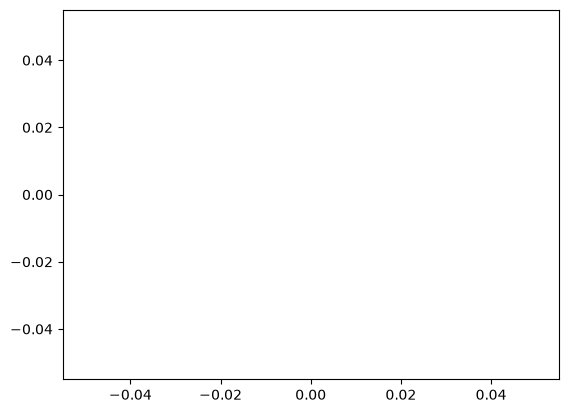

In [79]:
import matplotlib.pyplot as plt
plt.scatter(final_df['f1'], final_df['f2'], c = final_df['target'])

In [92]:
!pip  install imblearn
from imblearn.over_sampling import SMOTE
oversample  = SMOTE()


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [95]:
final_df = final_df.dropna(subset=['f1', 'f2', 'target'])

In [89]:
smote_df

,f1,f2,target
0,1.198971,1.293190,0
1,2.707180,3.723636,0
2,0.556906,-0.361418,0
3,0.134843,-0.769454,0
4,-1.871419,-0.517843,1
...,...,...,...
995,1.106642,1.675545,0
996,-0.020293,-0.747264,0
997,1.343474,1.709298,0
998,0.822423,0.619172,0


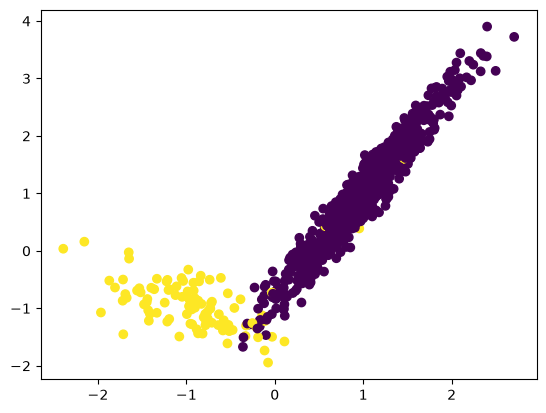

In [90]:
plt.scatter(smote_df['f1'], smote_df['f2'], c = smote_df['target'])